In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sqlite3

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_excel("/content/netflix_titles.xlsx")
print(df.shape)
df.head()

(8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25 00:00:00,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24 00:00:00,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24 00:00:00,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24 00:00:00,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24 00:00:00,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
df.info()
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0


In [4]:
mask = df['rating'].str.contains('min', na=False)
print("Rows to fix:", mask.sum())
df.loc[mask, 'duration'] = df.loc[mask, 'rating']
df.loc[mask, 'rating'] = np.nan

Rows to fix: 3


In [5]:
df['director'] = df['director'].fillna('Unknown')
df['cast']     = df['cast'].fillna('Unknown')
df['country']  = df['country'].fillna('Unknown')
df['rating']   = df['rating'].fillna('Not Rated')

for col in ['type', 'country', 'rating', 'listed_in']:
    df[col] = df[col].str.strip()

In [6]:
df['date_added'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce')
df['year_added']  = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month

In [7]:
df['duration_num'] = df['duration'].str.extract(r'(\d+)').astype(float)
df['duration_min'] = np.where(df['type'] == 'Movie', df['duration_num'], np.nan)
df['seasons']      = np.where(df['type'] == 'TV Show', df['duration_num'], np.nan)

In [8]:
df['genres'] = df['listed_in'].str.split(', ')
df['main_genre'] = df['genres'].str[0]

df['countries'] = df['country'].str.split(', ')
df['main_country'] = df['countries'].str[0].str.strip(',').str.strip()

rating_map = {
    'TV-Y': 'Kids', 'TV-Y7': 'Kids', 'TV-Y7-FV': 'Kids', 'TV-G': 'Kids', 'G': 'Kids',
    'PG': 'Older Kids', 'TV-PG': 'Older Kids',
    'PG-13': 'Teens', 'TV-14': 'Teens',
    'R': 'Adults', 'TV-MA': 'Adults', 'NC-17': 'Adults',
    'NR': 'Not Rated', 'UR': 'Not Rated', 'Not Rated': 'Not Rated'
}
df['age_group'] = df['rating'].map(rating_map)

In [9]:
df.to_csv("netflix_clean.csv", index=False)

sql_cols = ['show_id', 'type', 'title', 'main_country', 'main_genre', 'release_year',
            'year_added', 'month_added', 'rating', 'age_group', 'duration_min', 'seasons']

conn = sqlite3.connect("netflix.db")
df[sql_cols].to_sql("titles", conn, index=False, if_exists="replace")
pd.read_sql("SELECT type, COUNT(*) AS total FROM titles GROUP BY type", conn)

,type,total
0,Movie,6131
1,TV Show,2676


In [10]:
RED, GREY = "#E50914", "#564d4d"
PAL = {"Movie": RED, "TV Show": GREY}

df = pd.read_csv("netflix_clean.csv", parse_dates=["date_added"])
df["genres"] = df["listed_in"].str.split(", ")
df["countries"] = df["country"].str.split(", ").apply(lambda l: [c.strip(",").strip() for c in l])

/tmp/ipykernel_2290/2587875431.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index, y=counts.values, palette=PAL)


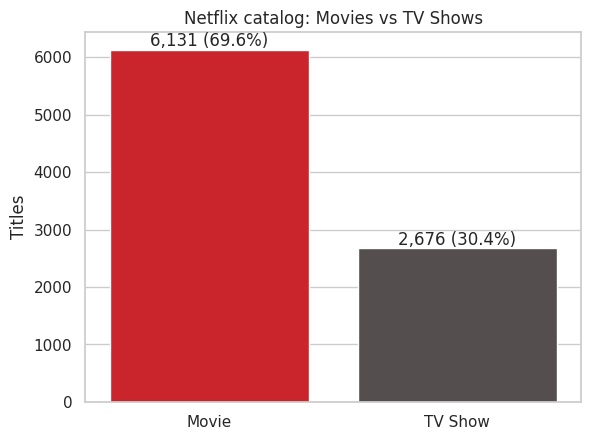

In [11]:
counts = df["type"].value_counts()
pct = (counts / counts.sum() * 100).round(1)
ax = sns.barplot(x=counts.index, y=counts.values, palette=PAL)
for i, (c, p) in enumerate(zip(counts.values, pct.values)):
    ax.text(i, c + 60, f"{c:,} ({p}%)", ha="center")
ax.set_title("Netflix catalog: Movies vs TV Shows")
ax.set_ylabel("Titles"); ax.set_xlabel("")
plt.show()

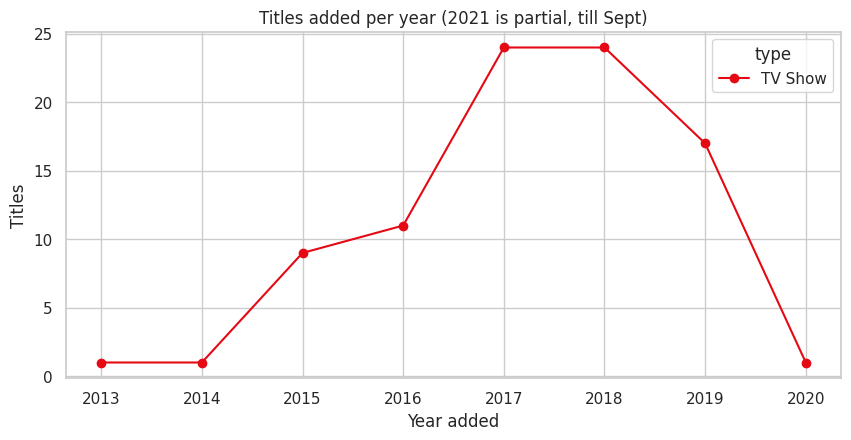

TV Show share of additions (%):
year_added
2013.0    100.0
2014.0    100.0
2015.0    100.0
2016.0    100.0
2017.0    100.0
2018.0    100.0
2019.0    100.0
2020.0    100.0


In [12]:
yearly = df.dropna(subset=["year_added"]).groupby(["year_added", "type"]).size().unstack(fill_value=0)
yearly = yearly[yearly.index >= 2012]
yearly.plot(marker="o", figsize=(10, 4.5), color=[RED, GREY])
plt.title("Titles added per year (2021 is partial, till Sept)")
plt.xlabel("Year added"); plt.ylabel("Titles")
plt.show()

share = (yearly["TV Show"] / yearly.sum(axis=1) * 100).round(1)
print("TV Show share of additions (%):"); print(share.to_string())

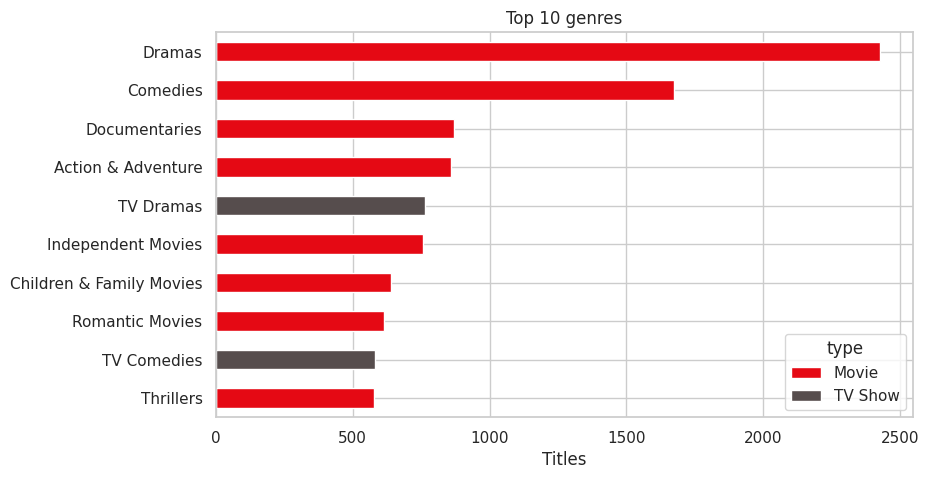

In [13]:
g = df.explode("genres")
g = g[~g["genres"].isin(["International Movies", "International TV Shows"])]
top = g.groupby(["genres", "type"]).size().unstack(fill_value=0)
top["total"] = top.sum(axis=1)
top = top.sort_values("total", ascending=False).head(10)

top[["Movie", "TV Show"]].iloc[::-1].plot.barh(stacked=True, figsize=(9, 5), color=[RED, GREY])
plt.title("Top 10 genres")
plt.xlabel("Titles"); plt.ylabel("")
plt.show()

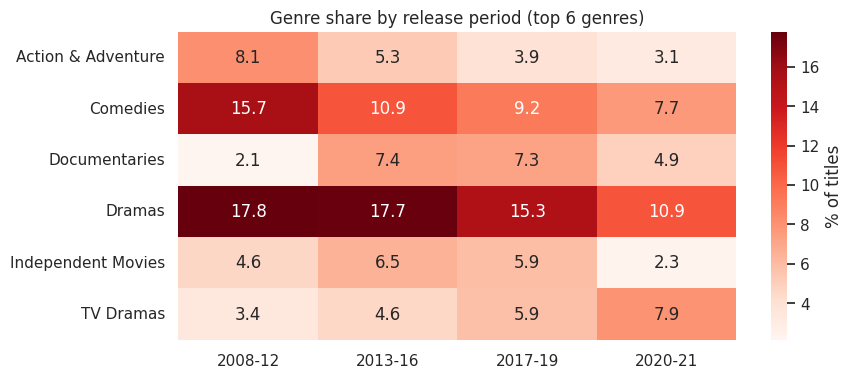

In [14]:
g = df.explode("genres")
g = g[~g["genres"].isin(["International Movies", "International TV Shows"])]
top6 = g["genres"].value_counts().head(6).index

g = g[g["release_year"] >= 2008]
g["period"] = pd.cut(g["release_year"], bins=[2007, 2012, 2016, 2019, 2021],
                     labels=["2008-12", "2013-16", "2017-19", "2020-21"])
mix = g[g["genres"].isin(top6)].groupby(["period", "genres"], observed=True).size().unstack(fill_value=0)
mix_pct = mix.div(g.groupby("period", observed=True).size(), axis=0) * 100

plt.figure(figsize=(9, 4))
sns.heatmap(mix_pct.T, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% of titles"})
plt.title("Genre share by release period (top 6 genres)")
plt.xlabel(""); plt.ylabel("")
plt.show()

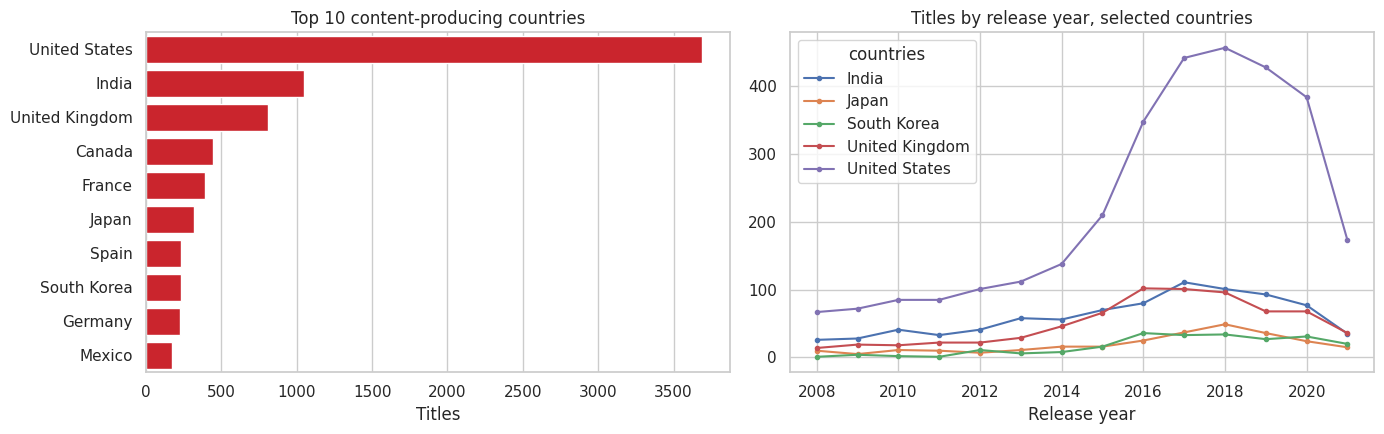

In [15]:
c = df.explode("countries")
c = c[c["countries"] != "Unknown"]
topc = c["countries"].value_counts().head(10)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=topc.values, y=topc.index, color=RED, ax=ax[0])
ax[0].set_title("Top 10 content-producing countries"); ax[0].set_xlabel("Titles"); ax[0].set_ylabel("")

sel = ["United States", "India", "United Kingdom", "South Korea", "Japan"]
t = c[c["countries"].isin(sel) & (c["release_year"] >= 2008)]
t = t.groupby(["release_year", "countries"]).size().unstack(fill_value=0)
t.plot(ax=ax[1], marker=".")
ax[1].set_title("Titles by release year, selected countries"); ax[1].set_xlabel("Release year")
plt.tight_layout(); plt.show()

In [16]:
cc = c["countries"].value_counts().reset_index()
cc.columns = ["country", "titles"]
fig = px.choropleth(cc, locations="country", locationmode="country names", color="titles",
                    color_continuous_scale="Reds", title="Netflix titles by country")
fig.show()

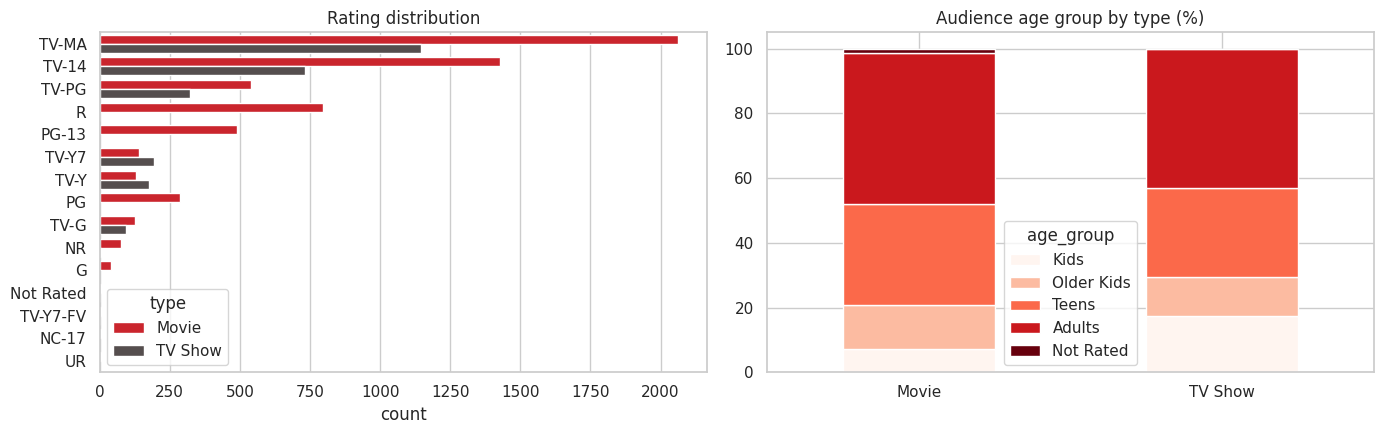

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

order = df["rating"].value_counts().index
sns.countplot(data=df, y="rating", hue="type", order=order, palette=PAL, ax=ax[0])
ax[0].set_title("Rating distribution"); ax[0].set_ylabel("")

ag = pd.crosstab(df["type"], df["age_group"], normalize="index") * 100
ag = ag[[x for x in ["Kids", "Older Kids", "Teens", "Adults", "Not Rated"] if x in ag.columns]]
ag.plot.bar(stacked=True, ax=ax[1], colormap="Reds")
ax[1].set_title("Audience age group by type (%)"); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

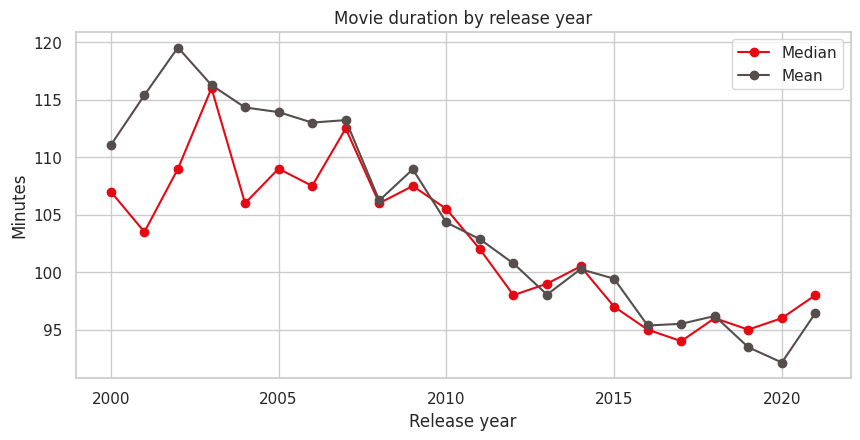

Share of movies under 90 min (%):
period
2000-09    16.8
2010-15    28.0
2016-21    34.7


In [18]:
m = df[(df["type"] == "Movie") & (df["release_year"] >= 2000)]
trend = m.groupby("release_year")["duration_min"].agg(["median", "mean", "count"])

plt.figure(figsize=(10, 4.5))
plt.plot(trend.index, trend["median"], marker="o", color=RED, label="Median")
plt.plot(trend.index, trend["mean"], marker="o", color=GREY, label="Mean")
plt.title("Movie duration by release year"); plt.xlabel("Release year"); plt.ylabel("Minutes"); plt.legend()
plt.show()

m = m.assign(period=pd.cut(m["release_year"], [1999, 2009, 2015, 2021], labels=["2000-09", "2010-15", "2016-21"]))
print("Share of movies under 90 min (%):")
print(m.groupby("period", observed=True)["duration_min"].apply(lambda s: (s < 90).mean() * 100).round(1).to_string())

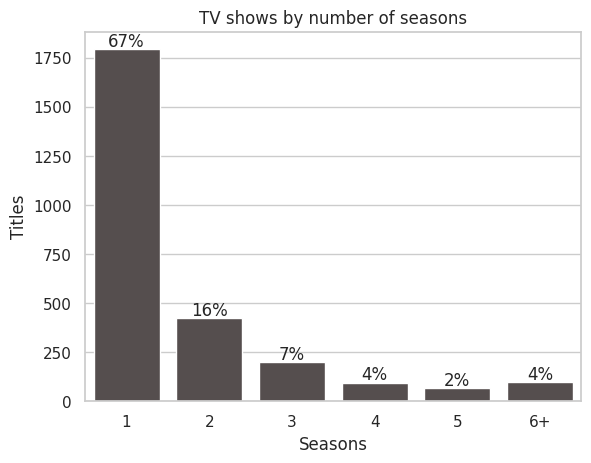

In [19]:
tv = df[df["type"] == "TV Show"]
s = tv["seasons"].value_counts().sort_index()
s = pd.concat([s[s.index <= 5], pd.Series({"6+": s[s.index > 5].sum()})])
s.index = s.index.map(lambda x: str(int(x)) if not isinstance(x, str) else x)

ax = sns.barplot(x=s.index, y=s.values, color=GREY)
for i, v in enumerate(s.values):
    ax.text(i, v + 15, f"{v/s.sum()*100:.0f}%", ha="center")
ax.set_title("TV shows by number of seasons"); ax.set_xlabel("Seasons"); ax.set_ylabel("Titles")
plt.show()

In [20]:
print(f"Total titles: {len(df):,}")
print(f"Movies: {(df.type=='Movie').mean()*100:.1f}% | TV shows: {(df.type=='TV Show').mean()*100:.1f}%")
print(f"Adult-rated titles: {(df.age_group=='Adults').mean()*100:.1f}%")
print(f"TV shows with 1 season: {(tv.seasons==1).mean()*100:.1f}%")
print(f"Median movie length: {df.duration_min.median():.0f} min")
print(f"US share: {c[c.countries=='United States'].show_id.nunique()/len(df)*100:.1f}%")
print(f"India share: {c[c.countries=='India'].show_id.nunique()/len(df)*100:.1f}%")

Total titles: 8,807
Movies: 69.6% | TV shows: 30.4%
Adult-rated titles: 45.5%
TV shows with 1 season: 67.0%
Median movie length: 98 min
US share: 41.9%
India share: 11.9%


In [21]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("/content/netflix.db")

df = pd.read_csv("/content/netflix_clean.csv")
df["genres"] = df["listed_in"].str.split(", ")
df["countries"] = df["country"].str.split(", ").apply(lambda l: [c.strip(",").strip() for c in l])

tg = df[["show_id", "genres"]].explode("genres").rename(columns={"genres": "genre"})
tg = tg[~tg["genre"].isin(["International Movies", "International TV Shows"])]
tg.to_sql("title_genres", conn, index=False, if_exists="replace")

tc = df[["show_id", "countries"]].explode("countries").rename(columns={"countries": "country"})
tc = tc[tc["country"] != "Unknown"]
tc.to_sql("title_countries", conn, index=False, if_exists="replace")

saved = {}
def q(name, sql):
    saved[name] = sql.strip()
    return pd.read_sql(sql, conn)

print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn))

              name
0           titles
1     title_genres
2  title_countries


In [22]:
q("Q1 - Movies vs TV Shows", """
SELECT type, COUNT(*) AS total,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM titles), 1) AS pct
FROM titles
GROUP BY type;
""")

,type,total,pct
0,Movie,6131,69.6
1,TV Show,2676,30.4


In [23]:
q("Q2 - Titles added per year", """
SELECT year_added,
       SUM(CASE WHEN type = 'Movie'   THEN 1 ELSE 0 END) AS movies,
       SUM(CASE WHEN type = 'TV Show' THEN 1 ELSE 0 END) AS tv_shows,
       COUNT(*) AS total,
       ROUND(100.0 * SUM(CASE WHEN type = 'TV Show' THEN 1 ELSE 0 END) / COUNT(*), 1) AS tv_share_pct
FROM titles
WHERE year_added >= 2012
GROUP BY year_added
ORDER BY year_added;
""")

,year_added,movies,tv_shows,total,tv_share_pct
0,2013.0,0,1,1,100.0
1,2014.0,0,1,1,100.0
2,2015.0,0,9,9,100.0
3,2016.0,0,11,11,100.0
4,2017.0,0,24,24,100.0
5,2018.0,0,24,24,100.0
6,2019.0,0,17,17,100.0
7,2020.0,0,1,1,100.0


In [24]:
q("Q3 - Top 10 genres", """
SELECT genre, COUNT(*) AS total
FROM title_genres
GROUP BY genre
ORDER BY total DESC
LIMIT 10;
""")

,genre,total
0,Dramas,2427
1,Comedies,1674
2,Documentaries,869
3,Action & Adventure,859
4,TV Dramas,763
5,Independent Movies,756
6,Children & Family Movies,641
7,Romantic Movies,616
8,TV Comedies,581
9,Thrillers,577


In [25]:
q("Q4 - Top 10 countries", """
SELECT country, COUNT(*) AS total
FROM title_countries
GROUP BY country
ORDER BY total DESC
LIMIT 10;
""")

,country,total
0,United States,3690
1,India,1046
2,United Kingdom,806
3,Canada,445
4,France,393
5,Japan,318
6,Spain,232
7,South Korea,231
8,Germany,226
9,Mexico,169


In [26]:
q("Q5 - Top genres in India (JOIN)", """
SELECT g.genre, COUNT(*) AS indian_titles
FROM titles t
JOIN title_genres g    ON t.show_id = g.show_id
JOIN title_countries c ON t.show_id = c.show_id
WHERE c.country = 'India'
GROUP BY g.genre
ORDER BY indian_titles DESC
LIMIT 5;
""")

,genre,indian_titles
0,Dramas,662
1,Comedies,323
2,Independent Movies,167
3,Action & Adventure,137
4,Romantic Movies,120


In [27]:
q("Q6 - Movie duration by period", """
SELECT CASE
         WHEN release_year BETWEEN 2000 AND 2009 THEN '2000-09'
         WHEN release_year BETWEEN 2010 AND 2015 THEN '2010-15'
         ELSE '2016-21'
       END AS period,
       COUNT(*) AS movies,
       ROUND(AVG(duration_min), 1) AS avg_minutes,
       ROUND(100.0 * SUM(CASE WHEN duration_min < 90 THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_under_90
FROM titles
WHERE type = 'Movie' AND release_year >= 2000 AND duration_min IS NOT NULL
GROUP BY period
ORDER BY period;
""")

,period,movies,avg_minutes,pct_under_90
0,2000-09,677,112.1,16.8
1,2010-15,1359,100.5,28.0
2,2016-21,3619,94.9,34.7


In [28]:
q("Q7 - Age group share within type", """
SELECT age_group, type, COUNT(*) AS total,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY type), 1) AS pct_within_type
FROM titles
GROUP BY age_group, type
ORDER BY type, total DESC;
""")

,age_group,type,total,pct_within_type
0,Adults,Movie,2862,46.7
1,Teens,Movie,1917,31.3
2,Older Kids,Movie,827,13.5
3,Kids,Movie,442,7.2
4,Not Rated,Movie,83,1.4
5,Adults,TV Show,1147,42.9
6,Teens,TV Show,733,27.4
7,Kids,TV Show,466,17.4
8,Older Kids,TV Show,323,12.1
9,Not Rated,TV Show,7,0.3


In [29]:
q("Q8 - Seasons distribution", """
SELECT CASE WHEN seasons >= 4 THEN '4+' ELSE CAST(CAST(seasons AS INT) AS TEXT) END AS seasons,
       COUNT(*) AS shows,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM titles WHERE type = 'TV Show'), 1) AS pct
FROM titles
WHERE type = 'TV Show'
GROUP BY 1
ORDER BY 1;
""")

,seasons,shows,pct
0,1,1793,67.0
1,2,425,15.9
2,3,199,7.4
3,4+,259,9.7


In [30]:
q("Q9 - Top genre per country", """
SELECT country, genre, titles FROM (
    SELECT c.country, g.genre, COUNT(*) AS titles,
           ROW_NUMBER() OVER (PARTITION BY c.country ORDER BY COUNT(*) DESC) AS rn
    FROM title_countries c
    JOIN title_genres g ON c.show_id = g.show_id
    WHERE c.country IN ('United States','India','United Kingdom','South Korea','Japan')
    GROUP BY c.country, g.genre
)
WHERE rn = 1;
""")

,country,genre,titles
0,India,Dramas,662
1,Japan,Anime Series,143
2,South Korea,Korean TV Shows,132
3,United Kingdom,British TV Shows,225
4,United States,Dramas,835


In [31]:
q("Q10 - Fastest growing countries", """
SELECT c.country,
       SUM(CASE WHEN t.release_year BETWEEN 2012 AND 2016 THEN 1 ELSE 0 END) AS titles_2012_16,
       SUM(CASE WHEN t.release_year BETWEEN 2017 AND 2021 THEN 1 ELSE 0 END) AS titles_2017_21,
       ROUND(100.0 * (SUM(CASE WHEN t.release_year BETWEEN 2017 AND 2021 THEN 1 ELSE 0 END)
                    - SUM(CASE WHEN t.release_year BETWEEN 2012 AND 2016 THEN 1 ELSE 0 END))
             / NULLIF(SUM(CASE WHEN t.release_year BETWEEN 2012 AND 2016 THEN 1 ELSE 0 END), 0), 0) AS growth_pct
FROM titles t
JOIN title_countries c ON t.show_id = c.show_id
GROUP BY c.country
HAVING titles_2012_16 >= 30
ORDER BY growth_pct DESC
LIMIT 8;
""")

,country,titles_2012_16,titles_2017_21,growth_pct
0,Spain,58,158,172.0
1,Mexico,41,106,159.0
2,China,44,97,120.0
3,Japan,75,161,115.0
4,United States,909,1884,107.0
5,South Korea,77,145,88.0
6,Australia,46,79,72.0
7,Belgium,33,51,55.0


In [32]:
with open("queries.sql", "w") as f:
    for name, sql in saved.items():
        f.write(f"-- {name}\n{sql}\n\n")

print("Saved", len(saved), "queries to queries.sql")

Saved 10 queries to queries.sql


         avg_min  pct_under_90
period                        
2000-09    112.1          16.8
2010-15    100.5          28.0
2016-21     94.9          34.7


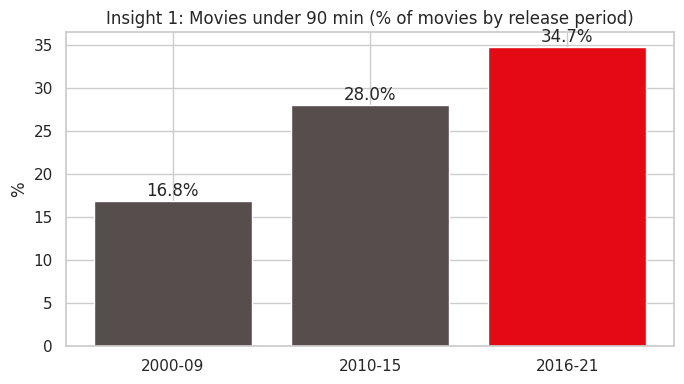

In [33]:
RED, GREY = "#E50914", "#564d4d"

# ---- Chart 1: Movies under 90 min ----
m = df[(df.type == "Movie") & (df.release_year >= 2000) & df.duration_min.notna()].copy()
m["period"] = pd.cut(m.release_year, [1999, 2009, 2015, 2021], labels=["2000-09", "2010-15", "2016-21"])
i1 = m.groupby("period", observed=True).agg(avg_min=("duration_min", "mean"),
        pct_under_90=("duration_min", lambda s: (s < 90).mean() * 100))
print(i1.round(1))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(i1.index.astype(str), i1.pct_under_90, color=[GREY, GREY, RED])
for i, v in enumerate(i1.pct_under_90):
    ax.text(i, v + 0.6, f"{v:.1f}%", ha="center")
ax.set_title("Insight 1: Movies under 90 min (% of movies by release period)")
ax.set_ylabel("%")
plt.tight_layout(); plt.savefig("memo_chart1_duration.png", dpi=150); plt.show()

                   a       b  growth
countries                           
Spain           58.0   158.0   172.0
Mexico          41.0   106.0   159.0
China           44.0    97.0   120.0
Japan           75.0   161.0   115.0
United States  909.0  1884.0   107.0
South Korea     77.0   145.0    88.0
Australia       46.0    79.0    72.0
Belgium         33.0    51.0    55.0


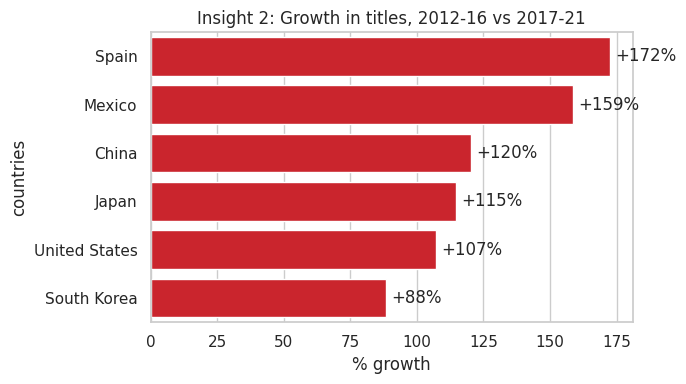

In [34]:
# ---- Chart 2: Country growth (2012-16 vs 2017-21) ----
c = df.explode("countries")
c = c[c["countries"] != "Unknown"]

a = c[c.release_year.between(2012, 2016)].groupby("countries").size()
b = c[c.release_year.between(2017, 2021)].groupby("countries").size()
g = pd.DataFrame({"a": a, "b": b}).dropna()
g = g[g.a >= 30]                       # removing small samples
g["growth"] = (g.b - g.a) / g.a * 100
g = g.sort_values("growth", ascending=False)
print(g.round(0).head(8))

top = g.head(6)
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=top.growth.values, y=top.index, color=RED, ax=ax)
for i, v in enumerate(top.growth.values):
    ax.text(v + 2, i, f"+{v:.0f}%", va="center")
ax.set_title("Insight 2: Growth in titles, 2012-16 vs 2017-21")
ax.set_xlabel("% growth")
plt.tight_layout(); plt.savefig("memo_chart2_countries.png", dpi=150); plt.show()

1 season: 67.0 %
3+ seasons: 17.1 %
1 season among shows released <=2018: 68.5 %


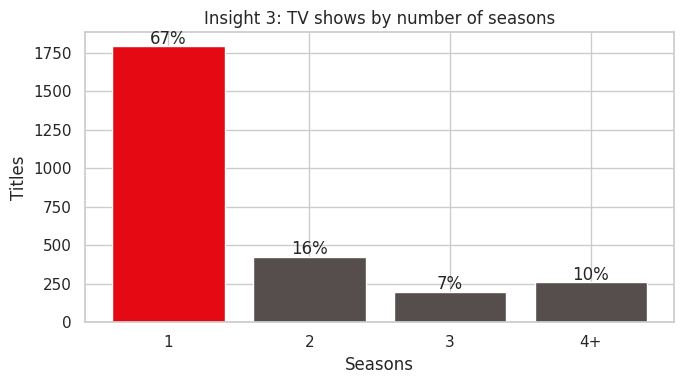

In [35]:
# ---- Chart 3: TV show seasons ----
tv = df[df.type == "TV Show"]
print("1 season:", round((tv.seasons == 1).mean() * 100, 1), "%")
print("3+ seasons:", round((tv.seasons >= 3).mean() * 100, 1), "%")
print("1 season among shows released <=2018:",
      round((tv[tv.release_year <= 2018].seasons == 1).mean() * 100, 1), "%")

s = tv.seasons.value_counts().sort_index()
s = pd.concat([s[s.index <= 3], pd.Series({"4+": s[s.index > 3].sum()})])
s.index = [str(int(x)) if not isinstance(x, str) else x for x in s.index]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(s.index, s.values, color=[RED, GREY, GREY, GREY])
for i, v in enumerate(s.values):
    ax.text(i, v + 15, f"{v/s.sum()*100:.0f}%", ha="center")
ax.set_title("Insight 3: TV shows by number of seasons")
ax.set_xlabel("Seasons"); ax.set_ylabel("Titles")
plt.tight_layout(); plt.savefig("memo_chart3_seasons.png", dpi=150); plt.show()